In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("../data/raw/garment_productivity.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [4]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   object 
 1   quarter                1197 non-null   object 
 2   department             1197 non-null   object 
 3   day                    1197 non-null   object 
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: f

,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
count,1197.000000,1197.000000,1197.000000,691.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000,1197.000000
mean,6.426901,0.729632,15.062172,1190.465991,4567.460317,38.210526,0.730159,0.369256,0.150376,34.609858,0.735091
std,3.463963,0.097891,10.943219,1837.455001,3348.823563,160.182643,12.709757,3.268987,0.427848,22.197687,0.174488
min,1.000000,0.070000,2.900000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.233705
25%,3.000000,0.700000,3.940000,774.500000,1440.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.650307
50%,6.000000,0.750000,15.260000,1039.000000,3960.000000,0.000000,0.000000,0.000000,0.000000,34.000000,0.773333
75%,9.000000,0.800000,24.260000,1252.500000,6960.000000,50.000000,0.000000,0.000000,0.000000,57.000000,0.850253
max,12.000000,0.800000,54.560000,23122.000000,25920.000000,3600.000000,300.000000,45.000000,2.000000,89.000000,1.120437


In [5]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
wip,506,42.272348
date,0,0.000000
quarter,0,0.000000
department,0,0.000000
day,0,0.000000
team,0,0.000000
targeted_productivity,0,0.000000
smv,0,0.000000
over_time,0,0.000000
incentive,0,0.000000


In [6]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


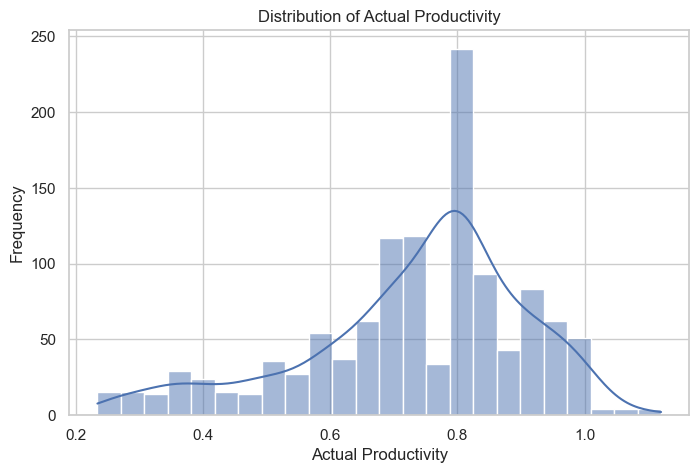

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["actual_productivity"],
    kde=True
)

plt.title("Distribution of Actual Productivity")
plt.xlabel("Actual Productivity")
plt.ylabel("Frequency")
plt.show()

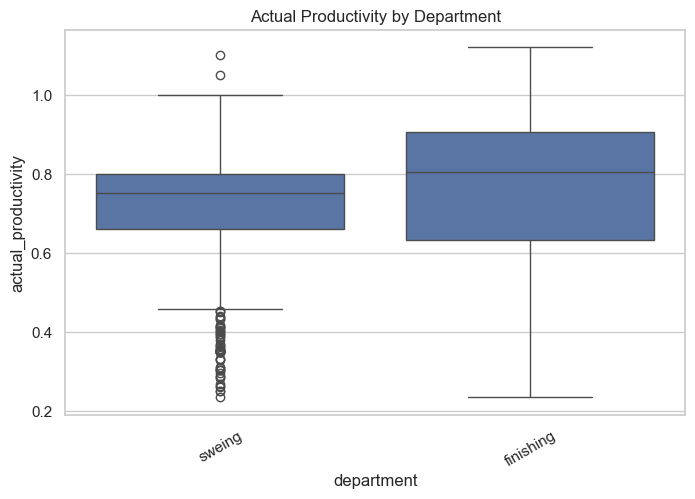

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="department",
    y="actual_productivity"
)

plt.title("Actual Productivity by Department")
plt.xticks(rotation=30)
plt.show()

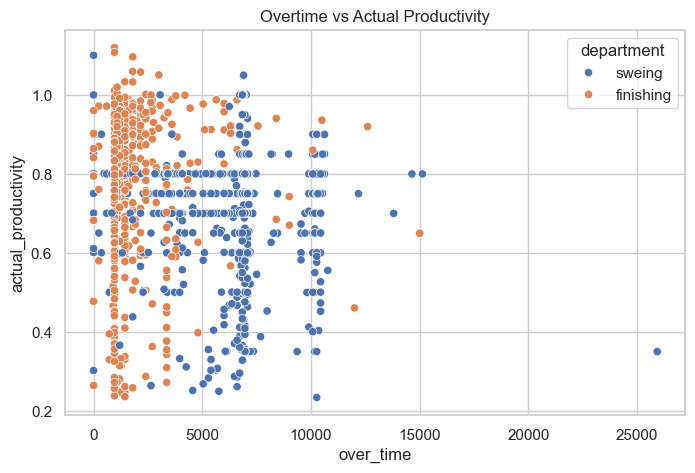

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="over_time",
    y="actual_productivity",
    hue="department"
)

plt.title("Overtime vs Actual Productivity")
plt.show()

In [10]:
wip_missing_by_department = df.groupby("department").agg(
    total_records=("wip", "size"),
    missing_wip=("wip", lambda x: x.isna().sum()),
    available_wip=("wip", lambda x: x.notna().sum())
)

wip_missing_by_department["missing_percentage"] = (
    wip_missing_by_department["missing_wip"]
    / wip_missing_by_department["total_records"] * 100
)

wip_missing_by_department

,total_records,missing_wip,available_wip,missing_percentage
department,,,,
finishing,506,506,0,100.0
sweing,691,0,691,0.0


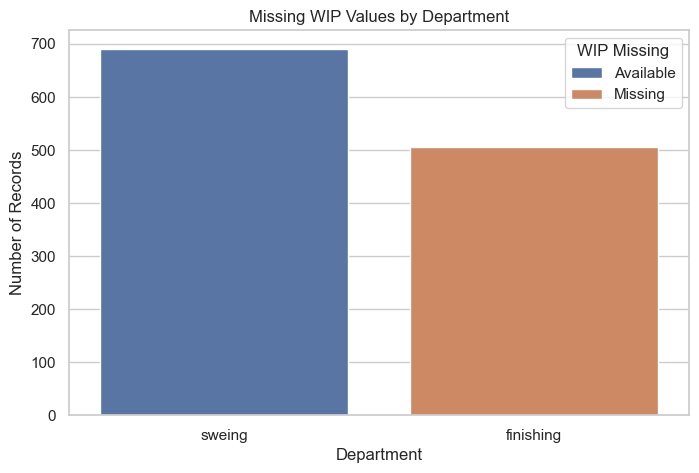

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="department",
    hue=df["wip"].isna()
)

plt.title("Missing WIP Values by Department")
plt.xlabel("Department")
plt.ylabel("Number of Records")
plt.legend(title="WIP Missing", labels=["Available", "Missing"])
plt.show()

In [12]:
df["wip_status"] = np.where(
    df["wip"].isna(),
    "Missing WIP",
    "Available WIP"
)

df.groupby("wip_status")["actual_productivity"].agg(
    ["count", "mean", "median", "min", "max"]
)

,count,mean,median,min,max
wip_status,,,,,
Available WIP,691,0.722013,0.750608,0.233705,1.100484
Missing WIP,506,0.752951,0.805909,0.235795,1.120437


In [13]:
df["department"].value_counts()

department
sweing       691
finishing    506
Name: count, dtype: int64

In [14]:
df["date"] = pd.to_datetime(
    df["date"],
    format="%m/%d/%Y"
)

print(df["date"].dtype)
print("Date range:", df["date"].min(), "to", df["date"].max())

datetime64[ns]
Date range: 2015-01-01 00:00:00 to 2015-03-11 00:00:00


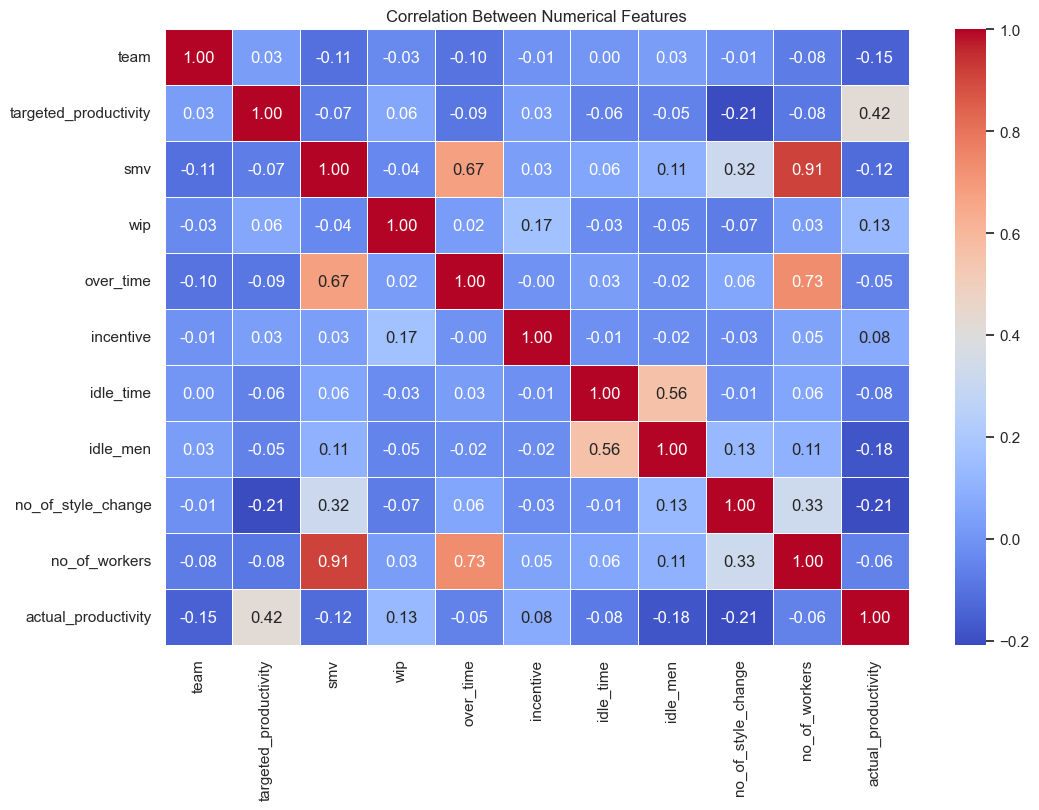

In [15]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")
plt.show()

In [16]:
productivity_corr = (
    correlation["actual_productivity"]
    .drop("actual_productivity")
    .sort_values(ascending=False)
)

print(productivity_corr)

targeted_productivity    0.421594
wip                      0.131147
incentive                0.076538
over_time               -0.054206
no_of_workers           -0.057991
idle_time               -0.080851
smv                     -0.122089
team                    -0.148753
idle_men                -0.181734
no_of_style_change      -0.207366
Name: actual_productivity, dtype: float64


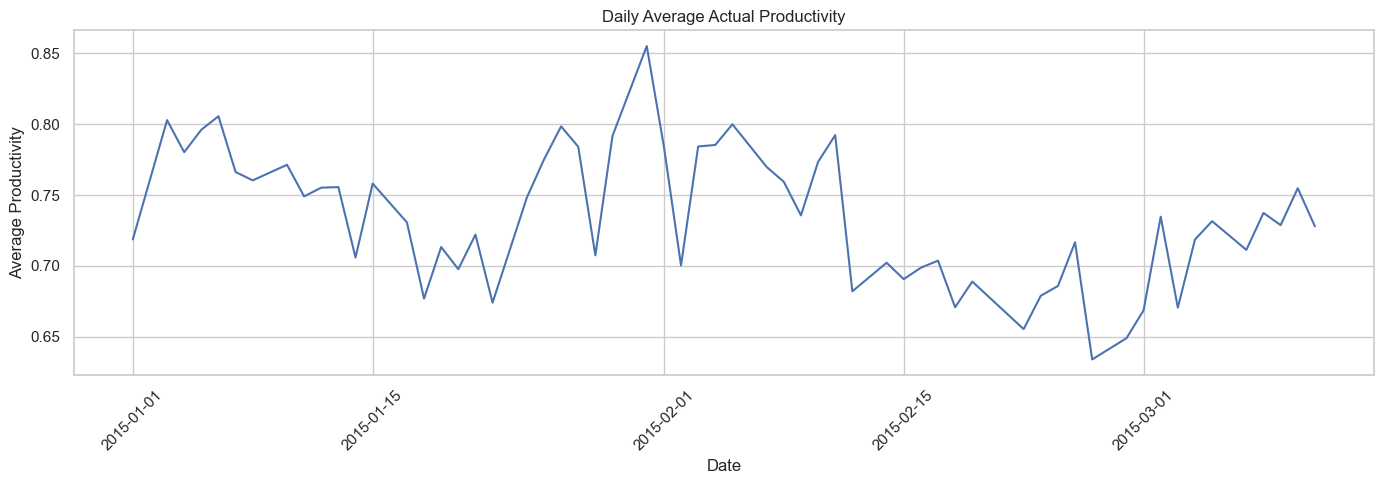

In [17]:
daily_productivity = (
    df.groupby("date")["actual_productivity"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 5))

sns.lineplot(
    data=daily_productivity,
    x="date",
    y="actual_productivity"
)

plt.title("Daily Average Actual Productivity")
plt.xlabel("Date")
plt.ylabel("Average Productivity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
daily_productivity = (
    df.groupby("date")["actual_productivity"]
    .agg(["mean", "min", "max", "count"])
    .reset_index()
)

daily_productivity.head(10)

,date,mean,min,max,count
0,2015-01-01,0.718711,0.436326,0.940725,19
1,2015-01-03,0.802773,0.625313,0.988025,21
2,2015-01-04,0.780174,0.345833,0.991389,21
3,2015-01-05,0.796027,0.600029,0.961059,22
4,2015-01-06,0.805508,0.616250,0.966781,21
5,2015-01-07,0.766212,0.330114,0.951420,22
6,2015-01-08,0.760329,0.233705,0.947689,22
7,2015-01-10,0.771305,0.337973,0.985000,22
8,2015-01-11,0.749045,0.452980,0.935322,23
9,2015-01-12,0.755194,0.246250,0.955152,23


In [19]:
highest_day = daily_productivity.loc[
    daily_productivity["mean"].idxmax()
]

lowest_day = daily_productivity.loc[
    daily_productivity["mean"].idxmin()
]

print("Highest productivity day:")
print(highest_day)

print("\nLowest productivity day:")
print(lowest_day)

Highest productivity day:
date     2015-01-31 00:00:00
mean                0.854955
min                 0.286985
max                 1.000457
count                     24
Name: 25, dtype: object

Lowest productivity day:
date     2015-02-26 00:00:00
mean                0.634143
min                 0.271875
max                 0.921704
count                     21
Name: 47, dtype: object


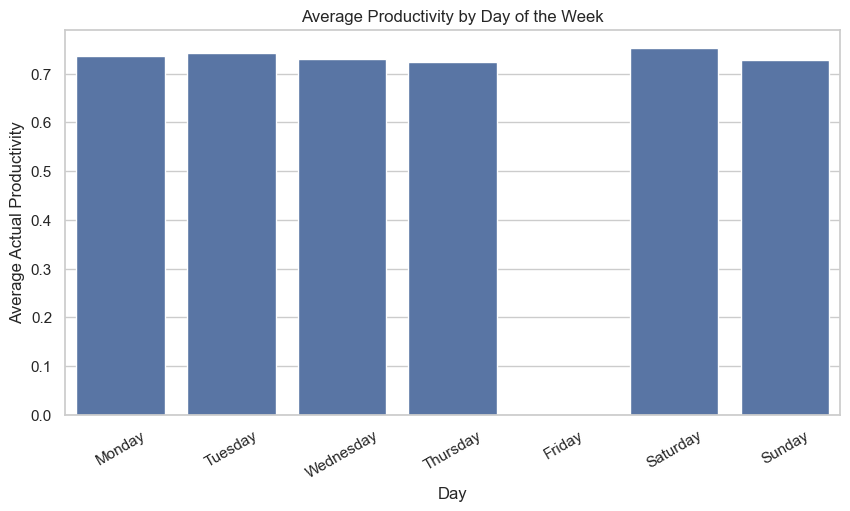

In [20]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="day",
    y="actual_productivity",
    order=day_order,
    errorbar=None
)

plt.title("Average Productivity by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Actual Productivity")
plt.xticks(rotation=30)
plt.show()

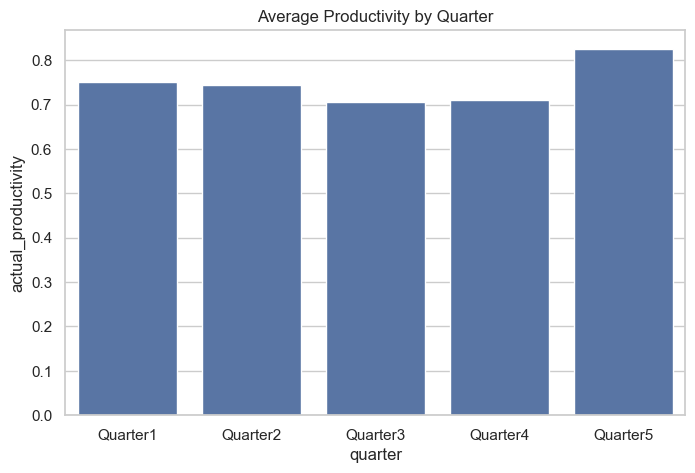

In [21]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="quarter",
    y="actual_productivity",
    errorbar=None
)

plt.title("Average Productivity by Quarter")
plt.show()